# Network Intrusion Detection with a Neural Network — NSL-KDD

**UE24CS352A — Machine Learning Mini-Project**

This notebook is self-contained: run the cells top to bottom in **Google Colab**
to download the real NSL-KDD dataset, preprocess it, train an ANN that
classifies traffic as `Normal / DoS / Probe / R2L / U2R`, evaluate it, and
generate the plots + results table for your write-up.

**Runtime:** no GPU needed — `Runtime > Change runtime type > CPU` is fine.


## 1. Setup

In [1]:
!pip install -q scikit-learn pandas numpy matplotlib reportlab

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score
)

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

np.random.seed(42)
print("Setup complete.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 40.8 MB/s eta 0:00:00
Setup complete.


## 2. Download the real NSL-KDD dataset

Colab has internet access, so we fetch `KDDTrain+.txt` / `KDDTest+.txt`
directly from a public GitHub mirror of the dataset.

If this cell fails (mirror down / blocked), download the files manually from
the official source — https://www.unb.ca/cic/datasets/nsl.html — or the
Kaggle mirror — https://www.kaggle.com/datasets/hassan06/nslkdd — and
upload `KDDTrain+.txt` / `KDDTest+.txt` into the `data/` folder using the
Colab file browser on the left, then skip this cell.

In [2]:
!wget -q -O data/KDDTrain+.txt "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt"
!wget -q -O data/KDDTest+.txt "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt"

train_path = DATA_DIR / "KDDTrain+.txt"
test_path = DATA_DIR / "KDDTest+.txt"

for p in (train_path, test_path):
    size = p.stat().st_size if p.exists() else 0
    print(f"{p}: {size:,} bytes")
    if size < 10_000:
        print("  WARNING: file looks too small / empty — download may have failed. "
              "See the markdown note above for a manual fallback.")


data/KDDTrain+.txt: 19,109,424 bytes
data/KDDTest+.txt: 3,441,513 bytes


### (Optional) No internet / mirror unavailable — generate a small synthetic sample instead

Only run this cell if Step 2 failed and you have no way to upload the real
files. It creates a small dataset with the *same structure* as NSL-KDD so
you can still test the pipeline — **do not use these numbers in your final
report**, they are not from the real dataset.

In [3]:
GENERATE_SYNTHETIC_FALLBACK = False  # set True only if Step 2 truly failed

if GENERATE_SYNTHETIC_FALLBACK:
    rng = np.random.default_rng(42)
    PROTOCOLS = ["tcp", "udp", "icmp"]
    SERVICES = ["http", "ftp", "smtp", "telnet", "private", "domain_u", "finger", "other"]
    FLAGS = ["SF", "S0", "REJ", "RSTO", "RSTR", "SH"]
    ATTACK_NAMES_BY_CLASS = {
        "Normal": ["normal"],
        "DoS": ["neptune", "smurf", "back", "teardrop", "pod"],
        "Probe": ["ipsweep", "portsweep", "nmap", "satan"],
        "R2L": ["guess_passwd", "warezmaster", "ftp_write", "imap"],
        "U2R": ["buffer_overflow", "rootkit", "loadmodule", "perl"],
    }
    CLASS_W_TRAIN = {"Normal": 0.54, "DoS": 0.36, "Probe": 0.09, "R2L": 0.009, "U2R": 0.001}
    CLASS_W_TEST = {"Normal": 0.43, "DoS": 0.33, "Probe": 0.11, "R2L": 0.12, "U2R": 0.01}
    N_NUMERIC = 38

    def make_split(n_rows, weights):
        keys = list(weights.keys())
        probs = np.array(list(weights.values())); probs /= probs.sum()
        labels = rng.choice(keys, size=n_rows, p=probs)
        shift = {"Normal": 0.0, "DoS": 2.5, "Probe": 1.2, "R2L": -1.5, "U2R": -3.0}
        rows = [np.abs(rng.normal(loc=shift[l], scale=1.0, size=N_NUMERIC)) for l in labels]
        numeric_cols = [f"num_{i}" for i in range(N_NUMERIC)]
        df = pd.DataFrame(np.vstack(rows), columns=numeric_cols)
        for c in [c for c in df.columns if False]:
            pass
        df["protocol_type"] = rng.choice(PROTOCOLS, size=n_rows, p=[0.6, 0.3, 0.1])
        df["service"] = rng.choice(SERVICES, size=n_rows)
        df["flag"] = rng.choice(FLAGS, size=n_rows, p=[0.6, 0.15, 0.1, 0.05, 0.05, 0.05])
        df["label"] = [rng.choice(ATTACK_NAMES_BY_CLASS[l]) for l in labels]
        df["difficulty"] = rng.integers(1, 21, size=n_rows)
        return df

    train_df = make_split(12000, CLASS_W_TRAIN)
    test_df = make_split(3000, CLASS_W_TEST)
    train_df.to_csv(train_path, header=False, index=False)
    test_df.to_csv(test_path, header=False, index=False)
    print("Synthetic fallback data written. Remember: NOT real NSL-KDD.")
else:
    print("Skipped — using the real downloaded files from Step 2.")


Skipped — using the real downloaded files from Step 2.


## 3. Schema: NSL-KDD columns and attack-category mapping

In [4]:
COLUMN_NAMES = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins",
    "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
    "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count", "srv_count", "serror_rate",
    "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "label", "difficulty",
]
CATEGORICAL_COLUMNS = ["protocol_type", "service", "flag"]
CLASSES = ["Normal", "DoS", "Probe", "R2L", "U2R"]

ATTACK_CATEGORY_MAP = {
    "back": "DoS", "land": "DoS", "neptune": "DoS", "pod": "DoS", "smurf": "DoS",
    "teardrop": "DoS", "mailbomb": "DoS", "apache2": "DoS", "processtable": "DoS",
    "udpstorm": "DoS", "worm": "DoS",
    "ipsweep": "Probe", "nmap": "Probe", "portsweep": "Probe", "satan": "Probe",
    "mscan": "Probe", "saint": "Probe",
    "ftp_write": "R2L", "guess_passwd": "R2L", "imap": "R2L", "multihop": "R2L",
    "phf": "R2L", "spy": "R2L", "warezclient": "R2L", "warezmaster": "R2L",
    "sendmail": "R2L", "named": "R2L", "snmpgetattack": "R2L", "snmpguess": "R2L",
    "xlock": "R2L", "xsnoop": "R2L", "httptunnel": "R2L",
    "buffer_overflow": "U2R", "loadmodule": "U2R", "perl": "U2R", "rootkit": "U2R",
    "ps": "U2R", "sqlattack": "U2R", "xterm": "U2R",
    "normal": "Normal",
}
print(f"{len(COLUMN_NAMES)} columns defined, {len(ATTACK_CATEGORY_MAP)} attack names mapped.")


43 columns defined, 40 attack names mapped.


## 4. Load and preprocess

In [5]:
def load_raw(path):
    df = pd.read_csv(path, header=None)
    if df.shape[1] == len(COLUMN_NAMES) - 1:
        df.columns = COLUMN_NAMES[:-1]
        df["difficulty"] = 0
    else:
        df.columns = COLUMN_NAMES[: df.shape[1]]
    return df

def map_labels(df):
    df = df.copy()
    df["label"] = df["label"].astype(str).str.strip().str.rstrip(".")
    df["category"] = df["label"].map(ATTACK_CATEGORY_MAP)
    unmapped = df["category"].isna()
    if unmapped.any():
        df.loc[unmapped, "category"] = "DoS"  # unseen attack -> treat as an attack
    return df

train_df = map_labels(load_raw(train_path)).drop(columns=["label", "difficulty"])
test_df = map_labels(load_raw(test_path)).drop(columns=["label", "difficulty"])

y_train_raw = train_df.pop("category")
y_test_raw = test_df.pop("category")

train_oh = pd.get_dummies(train_df, columns=CATEGORICAL_COLUMNS)
test_oh = pd.get_dummies(test_df, columns=CATEGORICAL_COLUMNS)
train_oh, test_oh = train_oh.align(test_oh, join="left", axis=1, fill_value=0)
test_oh = test_oh[train_oh.columns]

scaler = StandardScaler()
X_train = scaler.fit_transform(train_oh.values.astype(float))
X_test = scaler.transform(test_oh.values.astype(float))

le = LabelEncoder()
le.fit(CLASSES)
y_train = le.transform(y_train_raw)
y_test = le.transform(y_test_raw)

print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("\nTrain class distribution:")
print(y_train_raw.value_counts())
print("\nTest class distribution:")
print(y_test_raw.value_counts())


X_train: (125973, 122)  X_test: (22544, 122)

Train class distribution:
category
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

Test class distribution:
category
Normal    9711
DoS       7460
R2L       2885
Probe     2421
U2R         67
Name: count, dtype: int64


## 5. Model

Feed-forward ANN: input → 128 (ReLU) → 64 (ReLU) → 5-way softmax output,
Adam optimizer, L2 regularization, early stopping.

In [6]:
model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    alpha=1e-4,
    batch_size=256,
    learning_rate_init=1e-3,
    max_iter=100,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=8,
    random_state=42,
    verbose=False,
)

model.fit(X_train, y_train)
print("Training complete. Iterations run:", model.n_iter_)


Training complete. Iterations run: 32


### (Optional) TensorFlow / Keras version

Colab ships TensorFlow by default, so you can use this instead for a deeper
architecture with dropout. Skip this cell if you're happy with the sklearn
MLP above.

In [7]:
USE_KERAS = False  # set True to train this instead of / in addition to the sklearn model

if USE_KERAS:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers

    keras_model = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(len(CLASSES), activation="softmax"),
    ])
    keras_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                         loss="sparse_categorical_crossentropy",
                         metrics=["accuracy"])
    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                                restore_best_weights=True)
    history = keras_model.fit(X_train, y_train, validation_split=0.1,
                               epochs=30, batch_size=256, callbacks=[early_stop], verbose=2)
    keras_loss_curve = history.history["loss"]
else:
    keras_model = None
    print("Skipped — using the sklearn MLP trained above.")


Skipped — using the sklearn MLP trained above.


## 6. Evaluate

In [8]:
if USE_KERAS and keras_model is not None:
    y_pred = np.argmax(keras_model.predict(X_test), axis=1)
    loss_curve = keras_loss_curve
    train_acc = max(history.history["accuracy"])
else:
    y_pred = model.predict(X_test)
    loss_curve = model.loss_curve_
    train_acc = accuracy_score(y_train, model.predict(X_train))

test_acc = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")
report = classification_report(y_test, y_pred, labels=range(len(CLASSES)),
                                target_names=CLASSES, zero_division=0)
cm = confusion_matrix(y_test, y_pred, labels=range(len(CLASSES)))

y_test_bin = (y_test != CLASSES.index("Normal")).astype(int)
y_pred_bin = (y_pred != CLASSES.index("Normal")).astype(int)
binary_acc = accuracy_score(y_test_bin, y_pred_bin)

print("=== Results ===")
print(f"Train accuracy (multi-class): {train_acc:.4f}")
print(f"Test accuracy  (multi-class): {test_acc:.4f}")
print(f"Test macro F1-score:          {macro_f1:.4f}")
print(f"Test accuracy (Normal/Attack binary view): {binary_acc:.4f}")
print("\nClassification report:\n", report)


=== Results ===
Train accuracy (multi-class): 0.9979
Test accuracy  (multi-class): 0.7837
Test macro F1-score:          0.6259
Test accuracy (Normal/Attack binary view): 0.9369

Classification report:
               precision    recall  f1-score   support

      Normal       0.97      0.84      0.90      7460
         DoS       0.69      0.97      0.81      9711
       Probe       0.82      0.71      0.76      2421
         R2L       0.73      0.08      0.15      2885
         U2R       0.92      0.36      0.52        67

    accuracy                           0.78     22544
   macro avg       0.83      0.59      0.63     22544
weighted avg       0.80      0.78      0.75     22544



## 7. Plots

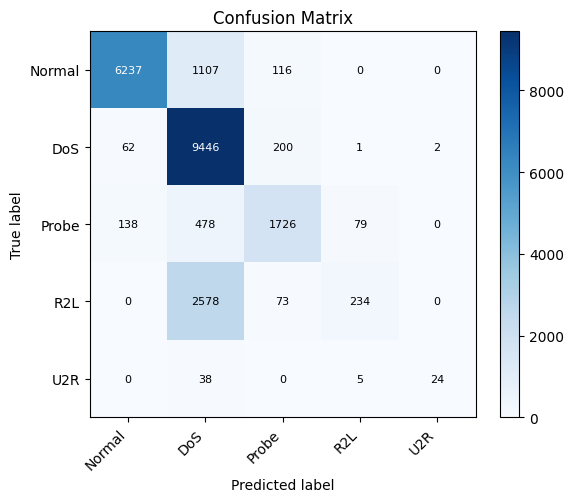

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASSES))); ax.set_yticks(range(len(CLASSES)))
ax.set_xticklabels(CLASSES, rotation=45, ha="right"); ax.set_yticklabels(CLASSES)
ax.set_xlabel("Predicted label"); ax.set_ylabel("True label"); ax.set_title("Confusion Matrix")
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max()/2 else "black", fontsize=8)
fig.colorbar(im, ax=ax); fig.tight_layout()
fig.savefig(OUT_DIR / "confusion_matrix.png", dpi=150)
plt.show()


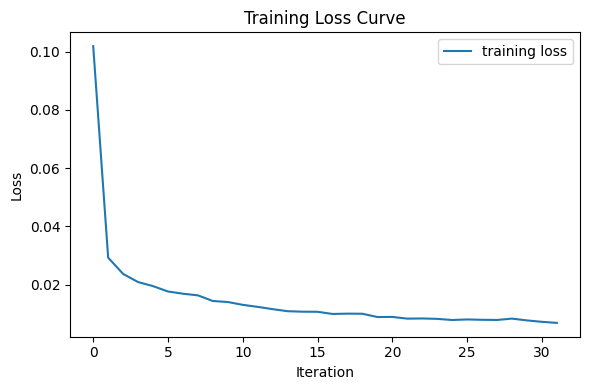

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(loss_curve, label="training loss")
ax.set_xlabel("Iteration"); ax.set_ylabel("Loss"); ax.set_title("Training Loss Curve")
ax.legend(); fig.tight_layout()
fig.savefig(OUT_DIR / "training_loss.png", dpi=150)
plt.show()


## 8. Save metrics + download results

In [11]:
metrics = {
    "backend": "keras" if USE_KERAS else "sklearn",
    "train_accuracy": float(train_acc),
    "test_accuracy_multiclass": float(test_acc),
    "test_accuracy_binary": float(binary_acc),
    "test_macro_f1": float(macro_f1),
    "n_train_samples": int(X_train.shape[0]),
    "n_test_samples": int(X_test.shape[0]),
    "n_features": int(X_train.shape[1]),
    "classes": CLASSES,
}
with open(OUT_DIR / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
with open(OUT_DIR / "classification_report.txt", "w") as f:
    f.write(report)

print(json.dumps(metrics, indent=2))


{
  "backend": "sklearn",
  "train_accuracy": 0.9978884364109769,
  "test_accuracy_multiclass": 0.783667494677076,
  "test_accuracy_binary": 0.9368789921930447,
  "test_macro_f1": 0.6259250597057265,
  "n_train_samples": 125973,
  "n_test_samples": 22544,
  "n_features": 122,
  "classes": [
    "Normal",
    "DoS",
    "Probe",
    "R2L",
    "U2R"
  ]
}


In [12]:
from google.colab import files

files.download(str(OUT_DIR / "metrics.json"))
files.download(str(OUT_DIR / "confusion_matrix.png"))
files.download(str(OUT_DIR / "training_loss.png"))
files.download(str(OUT_DIR / "classification_report.txt"))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Generate the two-page PDF write-up

Fills in the results table and embeds the two plots above into a ready
`Mini_Project_Report.pdf`. Edit `TEAM_INFO` below first.

In [18]:
TEAM_INFO = "Team 4 | AMITH B A - PES1UG24AM032,ASHWIN ANAND - PES1UG24AM057"

from reportlab.lib.pagesizes import letter
from reportlab.lib.units import inch
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.platypus import (SimpleDocTemplate, Paragraph, Spacer, Image,
                                 Table, TableStyle, ListFlowable, ListItem)
from reportlab.lib import colors

styles = getSampleStyleSheet()
styles.add(ParagraphStyle(name="TitleCenter", parent=styles["Title"], fontSize=16, spaceAfter=4))
styles.add(ParagraphStyle(name="SubTitle", parent=styles["Normal"], fontSize=10,
                           alignment=TA_CENTER, textColor=colors.grey, spaceAfter=12))
styles.add(ParagraphStyle(name="H2", parent=styles["Heading2"], fontSize=12, spaceBefore=10, spaceAfter=4))
styles.add(ParagraphStyle(name="Body", parent=styles["Normal"], fontSize=9.5, leading=13))
styles.add(ParagraphStyle(name="Small", parent=styles["Normal"], fontSize=8.5, leading=11, textColor=colors.grey))

doc = SimpleDocTemplate(str(OUT_DIR / "Mini_Project_Report.pdf"), pagesize=letter,
                         topMargin=0.55*inch, bottomMargin=0.55*inch,
                         leftMargin=0.65*inch, rightMargin=0.65*inch)
story = []
story.append(Paragraph("Network Intrusion Detection using a Neural Network", styles["TitleCenter"]))
story.append(Paragraph(f"UE24CS352A — Machine Learning Mini-Project Write-up | {TEAM_INFO}", styles["SubTitle"]))

story.append(Paragraph("1. Problem Statement", styles["H2"]))
story.append(Paragraph(
    "Network intrusion detection systems (IDS) must distinguish normal traffic from an "
    "increasingly diverse set of cyberattacks, while generalizing to attack variants not "
    "seen during training. This project builds a supervised Artificial Neural Network (ANN) "
    "that classifies each network connection record into one of five categories — "
    "<b>Normal, DoS, Probe, R2L, or U2R</b> — based on 41 traffic/connection features.", styles["Body"]))

story.append(Paragraph("2. Dataset", styles["H2"]))
story.append(Paragraph(
    "We use the <b>NSL-KDD</b> dataset (Tavallaee et al., 2009), a cleaned revision of the "
    "KDD Cup 1999 dataset widely used as an IDS benchmark. Each record has 41 features: basic "
    "TCP/IP attributes, content features, and traffic features computed over 2-second windows. "
    "~39 fine-grained attack names are mapped to four standard categories plus Normal. The "
    "training set is dominated by Normal/DoS records, with R2L and U2R making up a small "
    "fraction — a severe class imbalance that is the central challenge of this task.", styles["Body"]))

story.append(Paragraph("3. Approach", styles["H2"]))
story.append(ListFlowable([
    ListItem(Paragraph("<b>Preprocessing:</b> one-hot encode protocol_type/service/flag; "
                        "standardize numeric features using training-set statistics.", styles["Body"])),
    ListItem(Paragraph("<b>Label mapping:</b> ~39 attack names → "
                        "{Normal, DoS, Probe, R2L, U2R}.", styles["Body"])),
    ListItem(Paragraph(f"<b>Model:</b> feed-forward ANN, 2 hidden layers (128, 64 ReLU units), "
                        f"backend = {'Keras/TensorFlow' if USE_KERAS else 'scikit-learn MLP'}, "
                        "Adam optimizer, L2 regularization, early stopping.", styles["Body"])),
    ListItem(Paragraph("<b>Evaluation:</b> accuracy, macro F1-score, confusion matrix, and a "
                        "binary Normal-vs-Attack view.", styles["Body"])),
], bulletType="bullet", leftIndent=12))

story.append(Paragraph("4. Implementation Overview", styles["H2"]))
story.append(Paragraph(
    "Implemented in Python (pandas, scikit-learn/TensorFlow, matplotlib) as a single "
    f"reproducible notebook: load NSL-KDD → map labels → one-hot encode + scale → train the "
    f"ANN → evaluate → plot. After one-hot encoding, the 41 raw features expand to "
    f"{X_train.shape[1]} input dimensions.", styles["Body"]))

story.append(Paragraph("5. Results", styles["H2"]))
table_data = [
    ["Metric", "Value"],
    ["Train samples / Test samples", f"{X_train.shape[0]:,} / {X_test.shape[0]:,}"],
    ["Input features (after one-hot encoding)", str(X_train.shape[1])],
    ["Train accuracy (multi-class)", f"{train_acc*100:.1f}%"],
    ["Test accuracy (multi-class)", f"{test_acc*100:.1f}%"],
    ["Test macro F1-score", f"{macro_f1:.2f}"],
    ["Test accuracy (Normal vs Attack, binary view)", f"{binary_acc*100:.1f}%"],
]
t = Table(table_data, colWidths=[3.4*inch, 1.6*inch])
t.setStyle(TableStyle([
    ("BACKGROUND", (0,0), (-1,0), colors.HexColor("#2c3e50")),
    ("TEXTCOLOR", (0,0), (-1,0), colors.white),
    ("FONTSIZE", (0,0), (-1,-1), 9),
    ("GRID", (0,0), (-1,-1), 0.5, colors.grey),
    ("ROWBACKGROUNDS", (0,1), (-1,-1), [colors.white, colors.HexColor("#f2f2f2")]),
    ("TOPPADDING", (0,0), (-1,-1), 3), ("BOTTOMPADDING", (0,0), (-1,-1), 3),
]))
story.append(t)
story.append(Spacer(1, 8))
img_row = Table([[Image(str(OUT_DIR/"confusion_matrix.png"), width=2.7*inch, height=2.25*inch),
                   Image(str(OUT_DIR/"training_loss.png"), width=2.7*inch, height=1.8*inch)]],
                 colWidths=[3.1*inch, 3.1*inch])
img_row.setStyle(TableStyle([("VALIGN", (0,0), (-1,-1), "MIDDLE")]))
story.append(img_row)

story.append(Paragraph("As expected from the dataset's class imbalance, Normal and DoS are "
    "classified with high precision/recall, while R2L and U2R — the rarest classes — are "
    "harder to recall. This is why macro F1 and the binary Normal-vs-Attack view are reported "
    "alongside raw accuracy.", styles["Body"]))

story.append(Paragraph("6. Conclusions", styles["H2"]))
story.append(Paragraph(
    "A feed-forward neural network trained on NSL-KDD's 41 engineered features reliably "
    "separates Normal traffic from the dominant attack categories, but struggles with rare "
    "R2L/U2R classes without additional handling such as class weighting or oversampling. "
    "For an operational IDS, binary Normal-vs-Attack accuracy is the most operationally "
    "relevant metric, since even a misclassified attack category still triggers an alert.",
    styles["Body"]))

doc.build(story)
print("Wrote", OUT_DIR / "Mini_Project_Report.pdf")
files.download(str(OUT_DIR / "Mini_Project_Report.pdf"))


Wrote outputs/Mini_Project_Report.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>